# ANA-071: architecture recovery, inference stability and the Optuna search

This notebook reads the immutable RUN-184 outputs. It does not fit a new model,
repeat Optuna, alter the selected parameters, or import the current AdaptEnv package.
The figures and CSV/JSON tables are regenerated from archived values and coefficients.
The selected synthetic ensemble is assessed on all four recorded calibration seeds
and all four fresh confirmation seeds. The confirmation genotypes were disjoint
from calibration for this run; this is not an independent biological dataset.

Reproduce with the analysis's pinned environment and `notebooks/execute.py`.
RUN-184 must be restored at its recorded repository path. The source helper is
`architecture_tools.py`; all statistical definitions are explicit below.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, Markdown, display

here = Path.cwd().resolve()
root = next(path for path in (here, *here.parents) if (path / "AIM.md").is_file())
analysis_dir = root / "analyses/2026-11-24_ANA-071_run-184-trpb-architecture-calibration-and-landscape-adequacy"
sys.path.insert(0, str(analysis_dir / "notebooks"))
import architecture_tools as architecture

architecture.set_style()
data = architecture.analyze(root)
print("Frozen source:", root / "data/processed/aggregate-thermodynamic-gnk-calibration/RUN-184/outputs")
print("Recomputed losses:", data["summary"]["losses_recomputed"])

Frozen source: /Users/matthewspence/Documents/Documents/project-adapt-env/data/processed/aggregate-thermodynamic-gnk-calibration/RUN-184/outputs
Recomputed losses: {'calibration': 24.034136531319838, 'confirmation': 27.346298701640418}


## All 18 fitted targets, with every generator seed retained

For each panel, the reference is that panel's empirical auxiliary fit. The
calibration-only scale is held fixed: `sqrt(bootstrap variance + 0.05**2)`.
The plotted residual is `(synthetic summary - empirical summary) / scale`.
The objective is the mean of squared **ensemble-mean** residuals across the
18 summaries. It is not an R², likelihood, posterior, or calibrated goodness-of-fit
statistic. The four dots describe generator variability; they are not confidence
intervals or biological replicates. The two losses are checked against the frozen
result, and the weights are recomputed independently from the archived bootstraps.

Latent variance uses the uniform-product zero-sum gauge; it is not observed
fitness variance. The limits and occupancy are **auxiliary-inferred** sigmoid
quantities, not measured biochemical saturation. Pair top-10% energy share is
a coefficient concentration statistic, not Thornton's minimal-model T90 test.

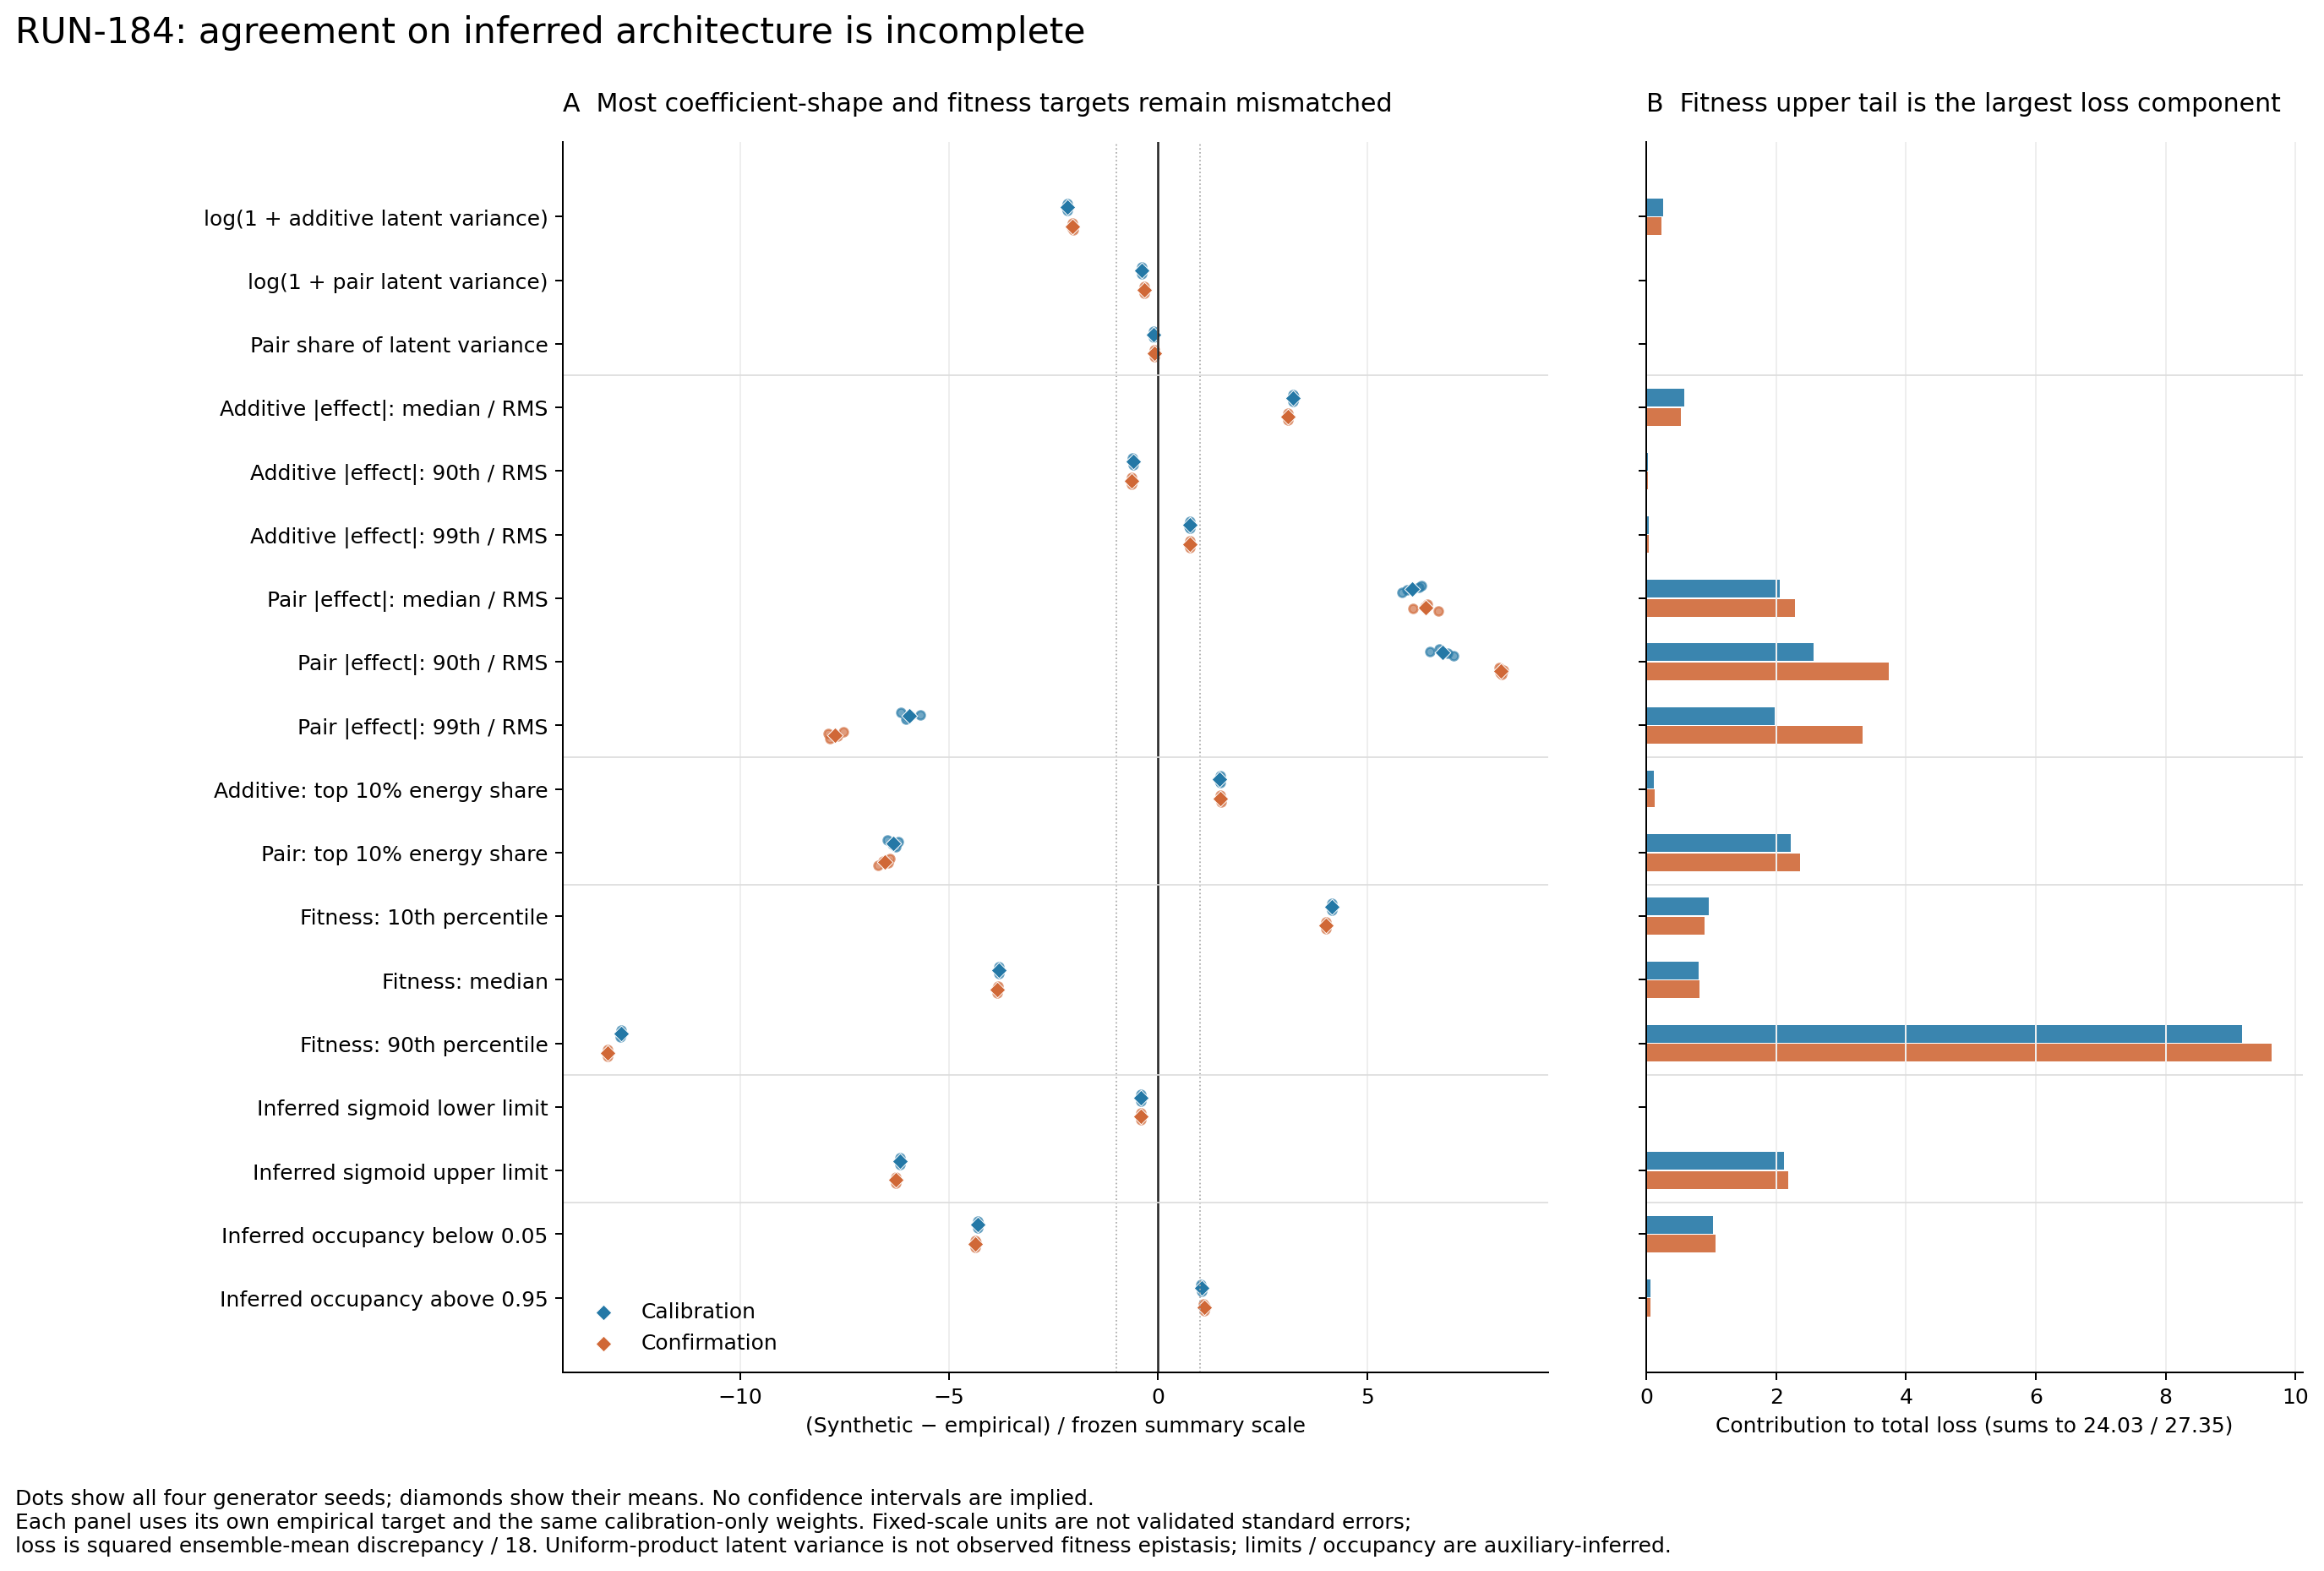

,label,empirical,synthetic_mean,synthetic_min,synthetic_max,standardized_mean_residual,loss_contribution
18,log(1 + additive latent variance),1.70804,1.59127,1.59062,1.59191,-2.05017,0.23351
19,log(1 + pair latent variance),0.06385,0.03339,0.03327,0.03345,-0.32302,0.00580
20,Pair share of latent variance,0.01438,0.00861,0.00858,0.00863,-0.09340,0.00048
21,Additive |effect|: median / RMS,0.65832,0.87704,0.87659,0.87743,3.10923,0.53707
22,Additive |effect|: 90th / RMS,1.51495,1.45904,1.45837,1.45946,-0.62900,0.02198
23,Additive |effect|: 99th / RMS,2.43528,2.61701,2.61175,2.61924,0.75679,0.03182
24,Pair |effect|: median / RMS,0.14792,0.66924,0.64460,0.69376,6.41036,2.28293
25,Pair |effect|: 90th / RMS,0.76127,1.65499,1.64997,1.66110,8.19841,3.73411
26,Pair |effect|: 99th / RMS,5.25326,2.56249,2.50568,2.63807,-7.73689,3.32553
27,Additive: top 10% energy share,0.40873,0.48857,0.48810,0.48928,1.49421,0.12404


In [2]:
architecture.plot_architecture(data)
display(Image(filename=str(data["figures"] / "03_architecture.png")))
import pandas as pd
summary_table = pd.read_csv(data["tables"] / "architecture_summary_aggregate.csv")
display(summary_table.loc[summary_table.panel == "confirmation", [
    "label", "empirical", "synthetic_mean", "synthetic_min", "synthetic_max", "standardized_mean_residual", "loss_contribution"
]].round(5))

## Empirical predictive value and bootstrap instability are separate findings

The archived **empirical calibration coefficients** can predict the disjoint
confirmation genotypes without refitting. This diagnostic tests the empirical
additive-plus-pairwise sigmoid architecture, using the exact archived intercept,
additive effects, pair matrices and readout. It is not the randomized synthetic
generator's predictive R², and that generator was not designed to recover
sequence-specific effects. Individual replicate R² and genotype-mean R² use
different denominators and are reported separately.

The selected-penalty internal CV scores are also retained for both panels and
all synthetic seeds. Their near-perfect synthetic values reflect inference on
noiseless data generated within the auxiliary model class. They do not establish
fidelity to TrpB. Empirical measurements retain assay noise.

All 20 bootstrap auxiliary fits converged, yet their inferred architectures
differ markedly from the original fit. The fixed scales use variation about the
bootstrap mean, not squared error about the original target. This instability
prevents treating those scales as validated uncertainty estimates. This analysis
diagnoses the shift; it does not prove its numerical or statistical cause.

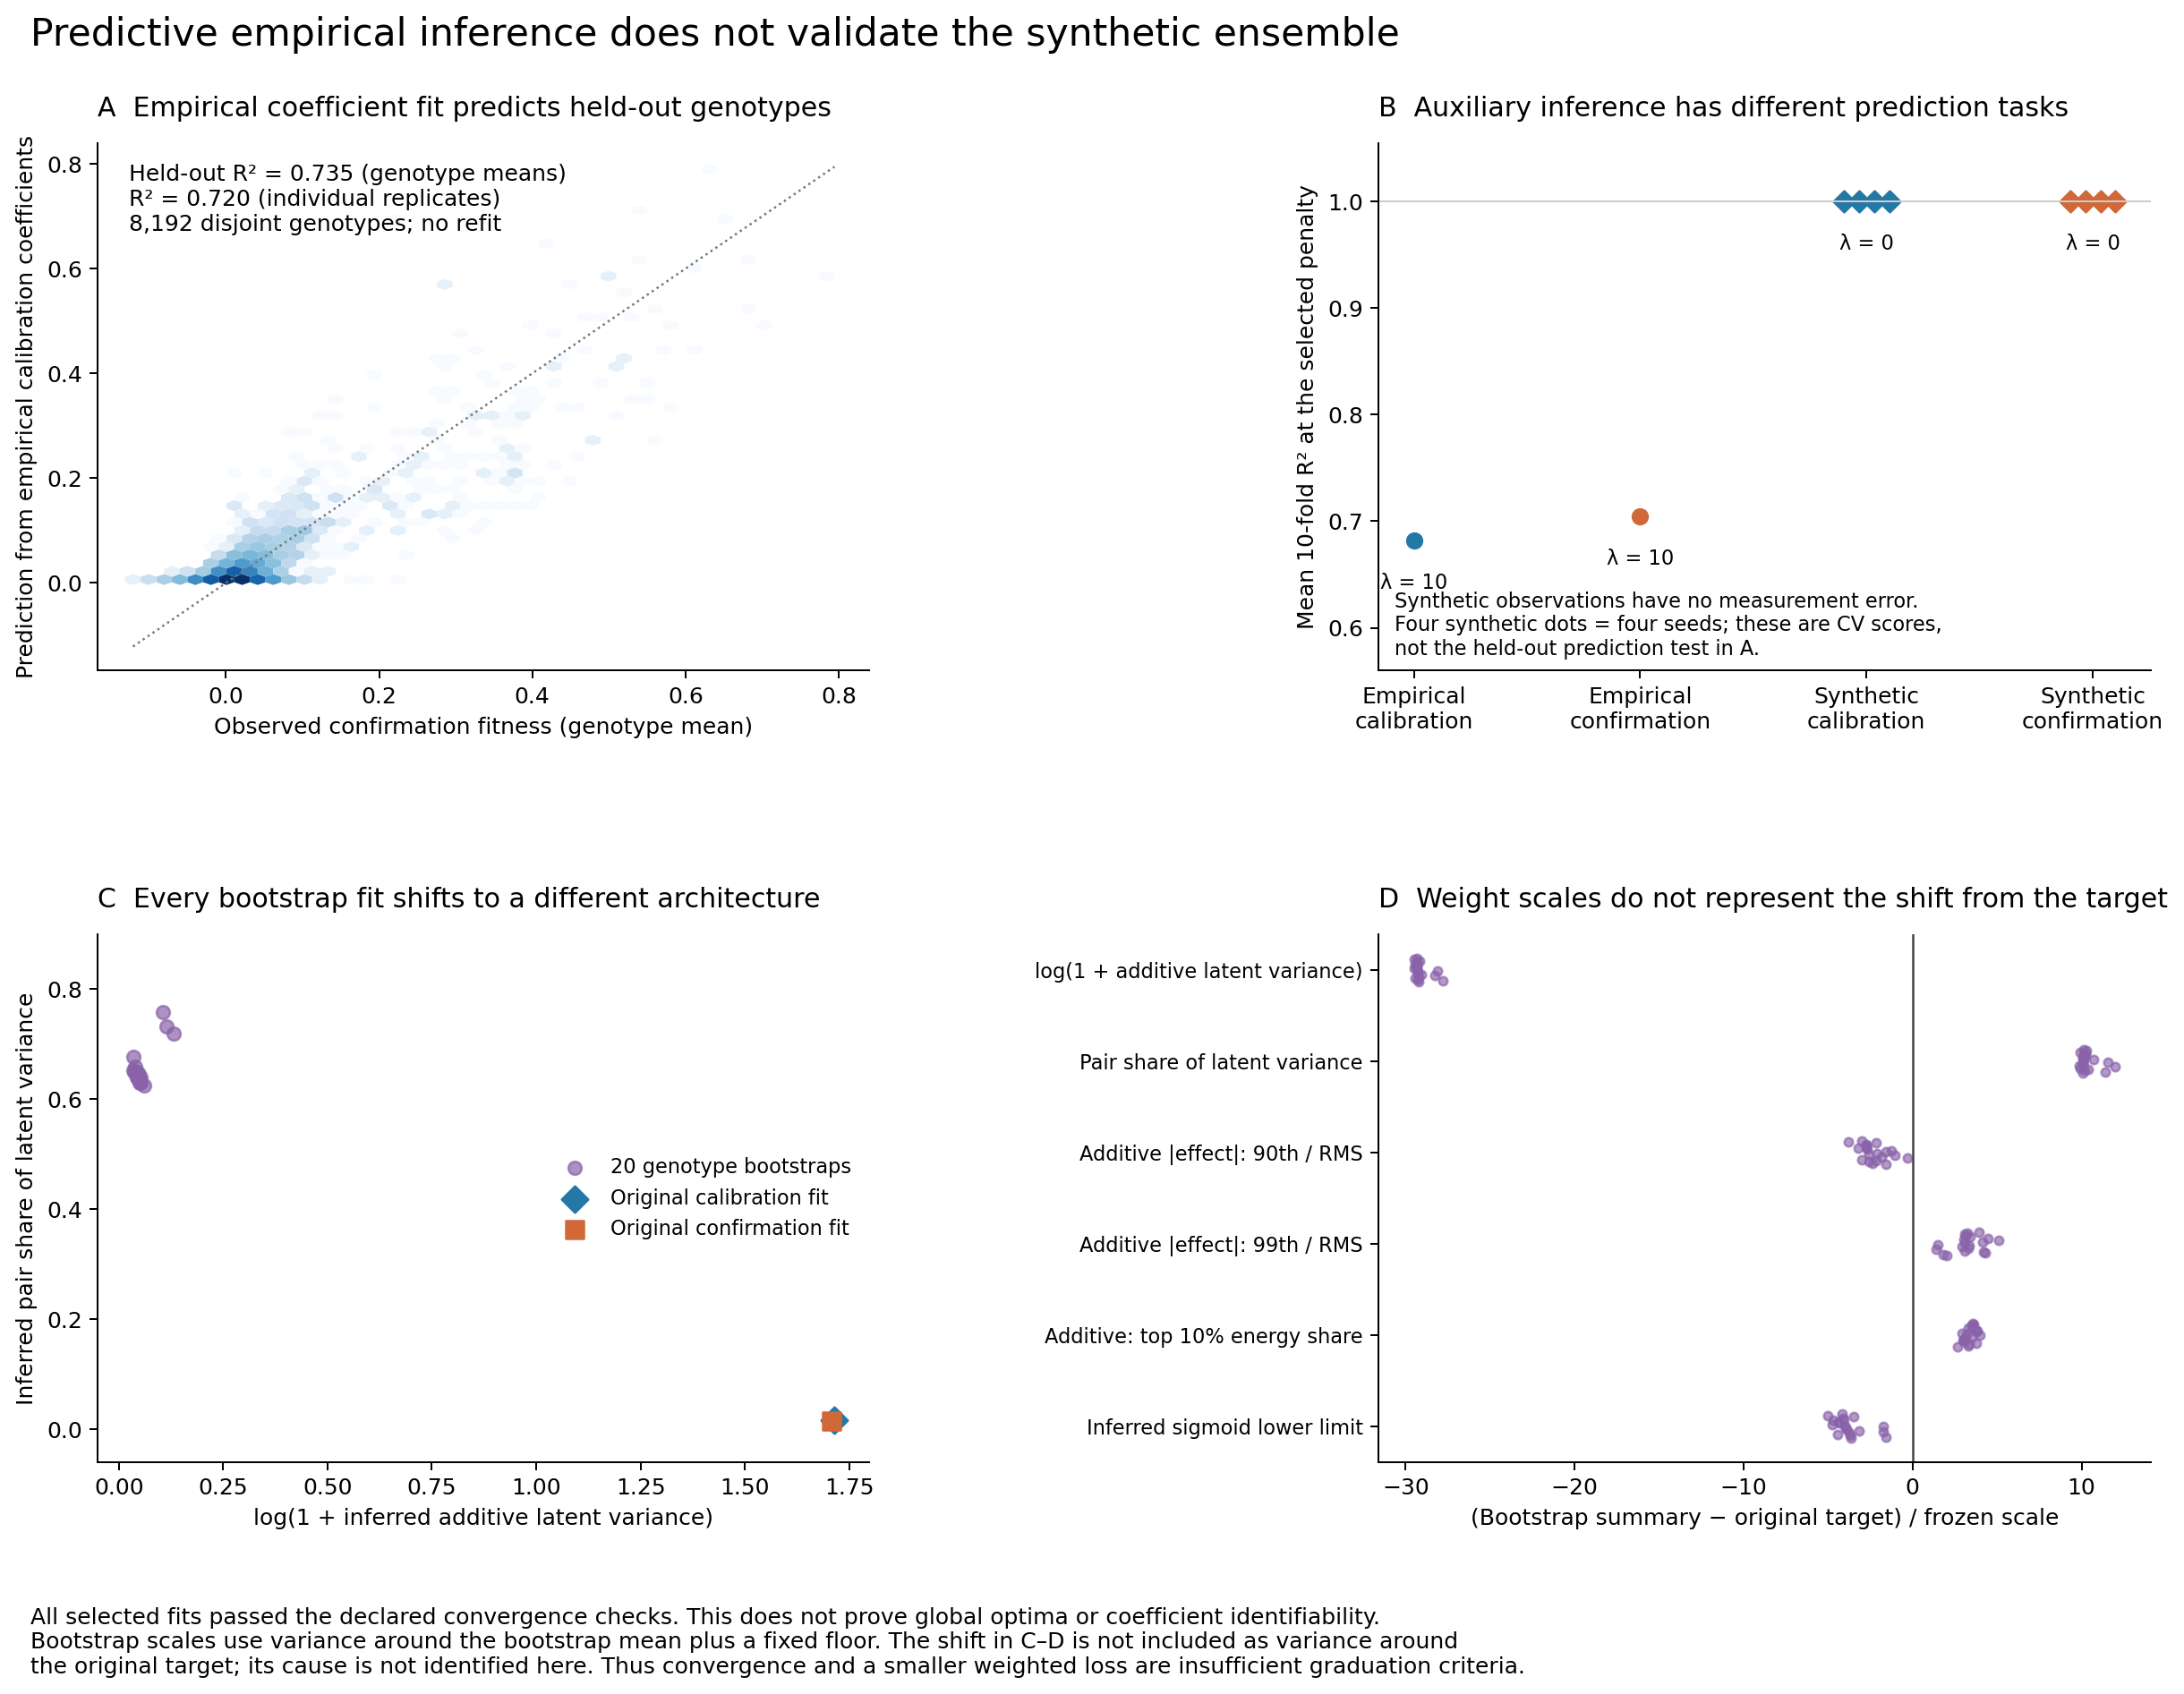

,0
model,empirical calibration coefficient model; not s...
genotypes,8192
individual_replicate_r2,0.720064
genotype_mean_r2,0.735389
genotype_mean_rmse,0.030051
fitting_scope,Empirical calibration coefficients; no refitti...


{'count': 20,
 'all_converged': True,
 'penalty_counts': {'10.0': 17, '1.0': 3},
 'additive_log1p_variance_target': 1.7143815390075117,
 'additive_log1p_variance_min_median_max': [0.034034159238248825,
  0.04622422105272148,
  0.1306987926871559],
 'pair_share_target': 0.015924318431188775,
 'pair_share_min_median_max': [0.624275743196725,
  0.6431814985563381,
  0.7580775568433211],
 'largest_mean_offset_in_fixed_scales': 29.119299779932508,
 'interpretation': 'Bootstrap architectures shift substantially from the original fit despite convergence. Causes are not identified; spread around shifted fits is not assurance of target uncertainty coverage.'}

In [3]:
architecture.plot_inference(data)
display(Image(filename=str(data["figures"] / "04_inference_and_weighting.png")))
display(pd.DataFrame([data["heldout"]]).T)
display(data["summary"]["bootstrap"])

## Search limitations and what alpha means in the selected model

Failed auxiliary inference does not receive a fabricated biological discrepancy.
Those failures nevertheless consume the 100-attempt search budget. The figure
marks every failed attempt and every successful loss, with the selected setting
overlaid on all six parameter projections. These are observations from a joint
adaptive search, not controlled one-parameter sweeps.

The registered `best loss + 1` near-best set contains one trial, not a confidence
region. The selected output span is near its lower search boundary and alpha
near its upper boundary. Neither the finite search nor numerical convergence
establishes a global optimum or parameter identifiability.

Raw pair coefficients use `J = sqrt(V) Z`, with `V ~ Gamma(alpha, rate=alpha)`
and `Z ~ Normal(0,1)`. Before table centering and realized RMS normalization,
`E[J²]=1`, `CV(V)=1/sqrt(alpha)`, and excess kurtosis of J is `3/alpha`.
Thus the selected alpha near 96 is close to Gaussian sampling, rather than a
strongly concentrated distribution. No Gaussian ablation was fitted in this run.
The generator's uniform-product latent pair variance fraction is
`r² / (2 + r²)`; sigmoid-transformed fitness epistasis is a different quantity.

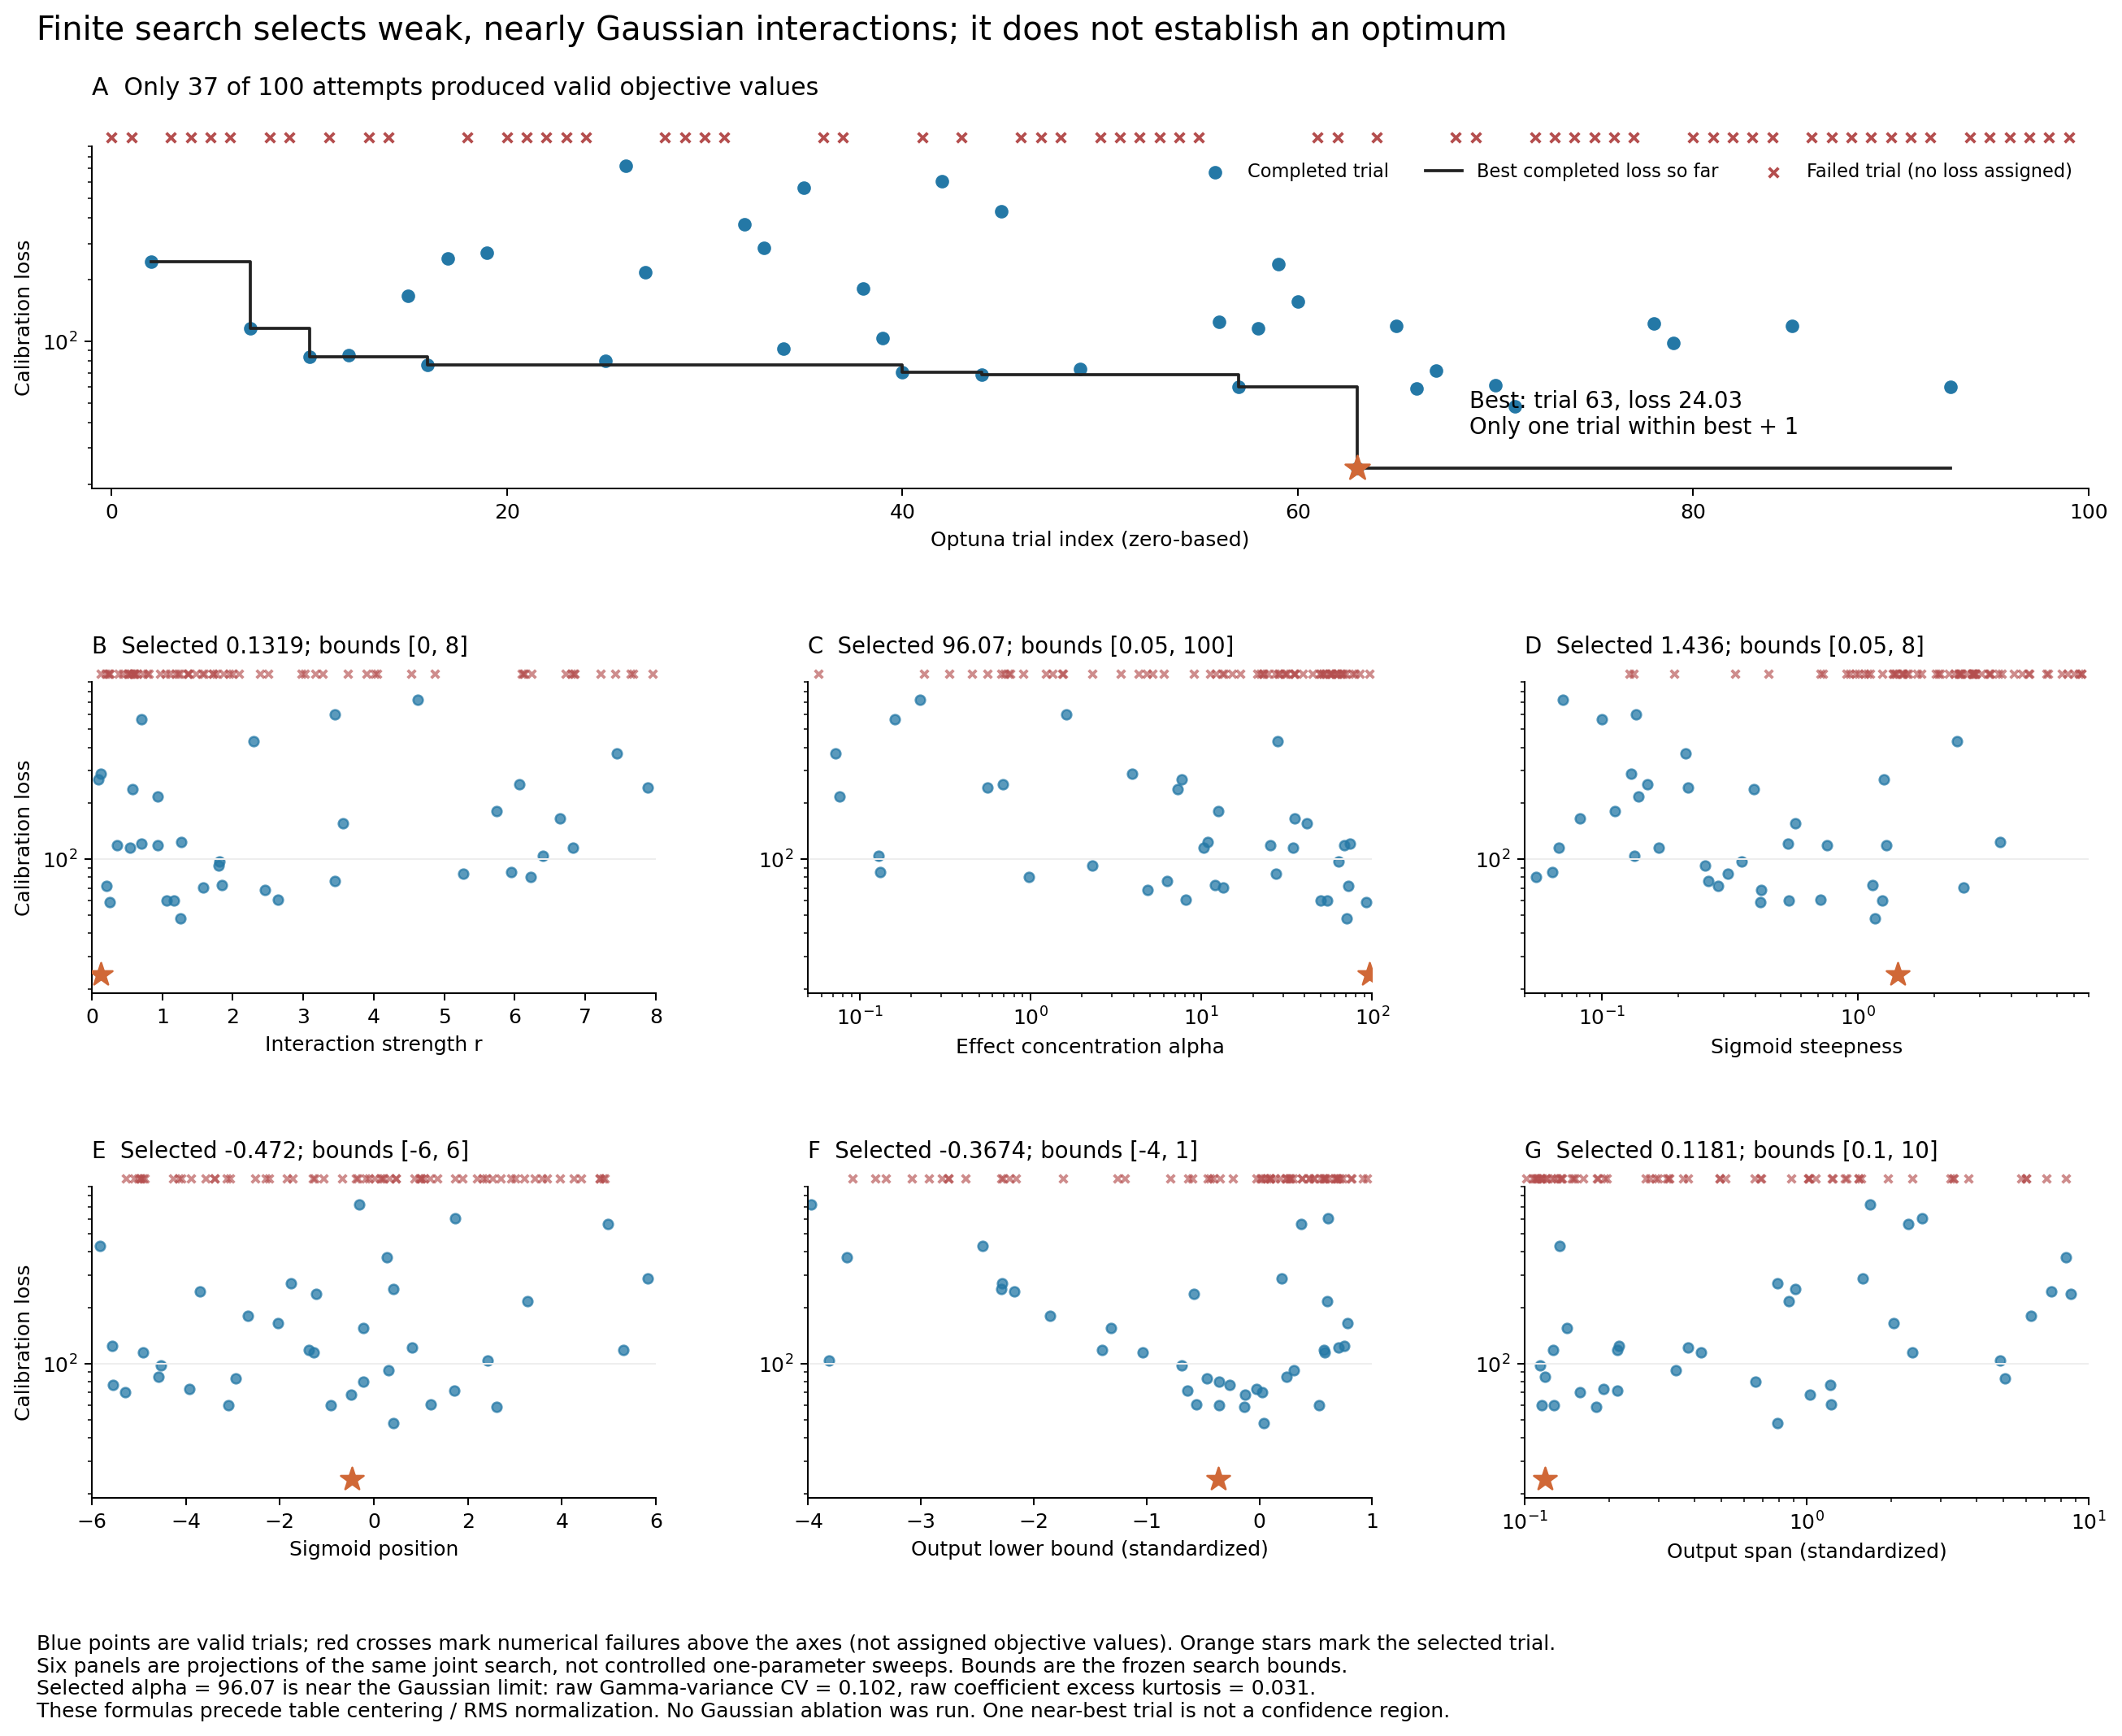

,parameter,selected_standardized,selected_native,lower_search_bound,upper_search_bound,search_is_log,position_in_search_coordinate,nearest_boundary_fraction_linear,near_best_trial_count,attempted_min,attempted_max,completed_min,completed_max
0,r,0.131867,0.131867,0.00,8.0,False,0.016483,0.016483,1,0.097407,7.958172,0.097407,7.881148
1,concentration,96.072275,96.072275,0.05,100.0,True,0.994728,0.039297,1,0.057310,96.485619,0.072181,96.072275
2,steepness,1.435740,1.435740,0.05,8.0,True,0.661536,0.174307,1,0.055283,7.488633,0.055283,3.605600
3,position,-0.472008,-0.472008,-6.00,6.0,False,0.460666,0.460666,1,-5.831872,5.831284,-5.831872,5.831284
4,lower,-0.367428,-0.001234,-4.00,1.0,False,0.726514,0.273486,1,-3.976793,0.954062,-3.976793,0.783720
5,span,0.118139,0.006987,0.10,10.0,True,0.036196,0.001832,1,0.101224,8.670015,0.113590,8.670015


{'alpha': 96.0722750010407,
 'raw_variance_mixture_cv': 0.10202367483541283,
 'raw_coefficient_excess_kurtosis': 0.03122649068076615,
 'latent_generator_pair_fraction': 0.008619479592415677,
 'interpretation': 'Near-Gaussian raw coefficient distribution. Formulas precede centering and realized RMS normalization. This run does not establish a benefit of finite-alpha concentration.'}

In [4]:
architecture.plot_search(data)
display(Image(filename=str(data["figures"] / "05_search_and_parameters.png")))
display(data["parameters"].round(6))
display(data["summary"]["gamma"])

## Interpretation boundary

RUN-184 establishes a reproducible completed calibration, not successful recovery
of the TrpB landscape. Several fitted targets remain far from the empirical
values, especially fitness spread and pair-coefficient concentration. The
empirical coefficient model has useful held-out prediction, while the sampled
synthetic ensemble does not inherit that agreement. Bootstrap instability,
extensive numerical failure and boundary-adjacent selection further limit the
fitted loss's interpretation. The companion landscape notebook assesses the
unfitted fitness, epistasis and graph diagnostics needed for the ANA's overall
graduation decision. No new fit, selection, release or default change occurs here.

In [5]:
print("Reproduction complete. Figures: 03_architecture, 04_inference_and_weighting, 05_search_and_parameters.")
print("Tables and quantitative narrative source:", data["tables"] / "architecture_findings.json")

Reproduction complete. Figures: 03_architecture, 04_inference_and_weighting, 05_search_and_parameters.
Tables and quantitative narrative source: /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-11-24_ANA-071_run-184-trpb-architecture-calibration-and-landscape-adequacy/tables/architecture_findings.json
